# RENDIMIENTO DEPORTIVO + C. AMBIENTALES

### Mario Hernández Padial
----


## OBJETIVO:
Pipeline ETL completo. Combinando mínimo 2 fuentes de datos distintas heterogéneas. Producir un dataset limpio y perfecto.
Requiere: una fuente en streaming, y una en bash.

Cada fila del dataset final, corresponderá con una respuesta del "formulario" que rellenaría el deportista con datos de la fuente stream.

Requisito: Pensar, describir, diseñar, en base a la plantilla.

## ENUNCIADO:

¿Entrenas peor cuando hace mucho calor? ¿La humedad afecta a tu resistencia? Este proyecto busca recoger registros de entrenamientos de un grupo de deportistas y cruzarlos con las condiciones meteorológicas del momento en que entrenaron.

El dataset final permitiría analizar si la temperatura, la humedad o el viento tienen impacto en el rendimiento percibido o en las métricas objetivas del entrenamiento.

**Fuentes de datos disponibles:**

- **Formulario de entrenamiento** (Google Forms): el deportista registra al terminar   el entrenamiento el tipo de deporte, duración, distancia, esfuerzo percibido (1-10)   y sensación general.
- **API Open-Meteo** (`https://api.open-meteo.com/v1/forecast`): temperatura, humedad   relativa, velocidad del viento, índice UV y precipitación, actualizada cada 15 minutos,   sin clave API.

---

### Por qué he seleccionado este tema:

Mi elección es debida a que parecen conjuntos de datos relativamente fáciles de manipular, y me parece un tema muy interesante. Creo que además con el desarrollo del curso podremos avanzar en la evolución de este proyecto.

---
## 1. Descripción de las fuentes de datos

### Fuente 1 — Formulario

| Campo | Descripción |
|-------|-------------|
| **Nombre** | Formulario de registro de entrenamiento |
| **Tipo de fuente** | Formulario web (Google Forms) |
| **URL o acceso** | Formulario creado en Google Forms (forms.google.com), vinculado a una hoja de Google Sheets donde se vuelcan las respuestas en tiempo real |
| **Formato de los datos** | Google Sheets sincronizado automáticamente; exportable como CSV o accesible mediante la API de Google Sheets |
| **Frecuencia de actualización** | Cada vez que un deportista envía el formulario (al terminar su entrenamiento) |
| **Quién lo rellena** | Grupo de deportistas voluntarios participantes en el estudio, una vez por sesión de entrenamiento |

**Campos del formulario:**

| Campo | Tipo de dato | Ejemplo de valor |
|-------|-------------|------------------|
| `timestamp` | fecha y hora (automático, generado por Google Forms al enviar) | 2025-05-15 08:32 |
| `id_deportista` | texto corto (código anónimo) | DEP-014 |
| `tipo_deporte` | opción múltiple (running, ciclismo, natación, fútbol, otro) | running |
| `duracion_min` | número | 45 |
| `distancia_km` | número (decimal, opcional según deporte) | 8.2 |
| `esfuerzo_percibido` | número (escala 1-10) | 7 |
| `sensacion_general` | opción múltiple (muy mal, mal, normal, bien, muy bien) | bien |
| `ubicacion` | texto o lista desplegable (ciudad/zona de entrenamiento) | Granada |


### Fuente 2 — API en tiempo real

| Campo | Descripción |
|-------|-------------|
| **Nombre** | Open-Meteo Forecast API |
| **Tipo de fuente** | API REST pública |
| **URL base** | `https://api.open-meteo.com/v1/forecast` |
| **Formato de respuesta** | JSON |
| **Frecuencia de actualización** | Cada 15 minutos (datos `current`) |
| **Autenticación necesaria** | No requiere clave API |

**Parámetros de la petición:**

| Parámetro | Valor | Para qué sirve |
|-----------|-------|----------------|
| `latitude` | 37.18 | Coordenada de la zona de entrenamiento (según `ubicacion` del formulario) |
| `longitude` | -3.60 | Coordenada de la zona de entrenamiento |
| `current` | temperature_2m,relative_humidity_2m,wind_speed_10m,uv_index,precipitation | Indica qué variables meteorológicas instantáneas se solicitan |
| `timezone` | Europe/Madrid | Asegura que las horas devueltas coincidan con la hora local del formulario |

**Campos de la respuesta que usaría:**

| Campo de la API | Tipo | Qué representa |
|-----------------|------|----------------|
| `current.time` | fecha y hora | Instante exacto de la lectura meteorológica |
| `current.temperature_2m` | número (°C) | Temperatura del aire a 2 metros |
| `current.relative_humidity_2m` | número (%) | Humedad relativa |
| `current.wind_speed_10m` | número (km/h) | Velocidad del viento a 10 metros |
| `current.uv_index` | número | Índice de radiación ultravioleta |
| `current.precipitation` | número (mm) | Precipitación acumulada en el intervalo |


---
## 2 Diseño del ds final

### 2.1 Esquema de columnas

| Columna | Tipo | Origen | Descripción |
|---------|------|--------|-------------|
| `timestamp` | datetime | Formulario | Fecha y hora en que el deportista envió el formulario al terminar el entrenamiento |
| `id_deportista` | texto | Formulario | Código anónimo del participante |
| `tipo_deporte` | categórico | Formulario | Running, ciclismo, natación, fútbol u otro |
| `duracion_min` | numérico (entero) | Formulario | Duración del entrenamiento en minutos |
| `distancia_km` | numérico (decimal) | Formulario | Distancia recorrida, cuando aplica al deporte |
| `esfuerzo_percibido` | numérico (1-10) | Formulario | Esfuerzo subjetivo percibido por el deportista |
| `sensacion_general` | categórico | Formulario | Muy mal, mal, normal, bien, muy bien |
| `ubicacion` | texto | Formulario | Ciudad/zona donde entrenó, usada para geolocalizar la consulta a la API |
| `temp_c` | numérico (decimal) | API | Temperatura del aire (°C) en el momento del entrenamiento |
| `humedad_pct` | numérico (entero) | API | Humedad relativa (%) |
| `viento_kmh` | numérico (decimal) | API | Velocidad del viento (km/h) |
| `uv_index` | numérico (decimal) | API | Índice de radiación ultravioleta |
| `precipitacion_mm` | numérico (decimal) | API | Precipitación acumulada (mm) en el intervalo de la lectura |


### 2.2 Ejemplo de fila

| Columna | Valor |
|---------|-------|
| `timestamp` | 2025-05-15 08:32 |
| `id_deportista` | DEP-014 |
| `tipo_deporte` | running |
| `duracion_min` | 45 |
| `distancia_km` | 8.2 |
| `esfuerzo_percibido` | 7 |
| `sensacion_general` | bien |
| `ubicacion` | Granada |
| `temp_c` | 19.4 |
| `humedad_pct` | 62 |
| `viento_kmh` | 11.3 |
| `uv_index` | 4.1 |
| `precipitacion_mm` | 0.0 |


### 2.3 Formatos de exportación

| Formato | Justificación |
|---------|---------------|
| CSV | Fácil de compartir con el equipo técnico/investigadores que trabajan con Excel, R o Python; formato universal para análisis estadístico puntual |
| Parquet | Formato columnar, comprimido y tipado, ideal para almacenar el histórico del dataset que crecerá con cada entrenamiento, y para cargarlo eficientemente en pandas/Spark en fases posteriores de análisis |


---
## 3. Diseño del pipeline

### 3.1 Descripción por etapas



**Etapa 1 — Extracción del formulario**

Las respuestas, por ejemplo, se recogen mediante Google Forms, vinculado a una hoja de Google Sheets que se actualiza en el instante en que el deportista pulsa "Enviar". El acceso se haría mediante la API de Google Sheets (`gspread` o `google-api-python-client` según la IA), consultando solo las filas nuevas desde la última ejecución (comparando el número de fila ya procesado o el `timestamp` máximo guardado). Como alternativa más simple, se podría programar una descarga periódica del Sheet como CSV (por ejemplo cada 10 minutos).

Si el deportista deja campos en blanco (por ejemplo `distancia_km` en deportes como natación en piscina, donde no siempre se mide), el campo llega vacío o como `NaN` tras la lectura con pandas. Los campos obligatorios (`tipo_deporte`, `duracion_min`, `esfuerzo_percibido`) se marcarían como obligatorios en el propio formulario para minimizar este problema; los campos opcionales se tratan en la etapa de limpieza (Etapa 4).

---

**Etapa 2 — Extracción de la API en tiempo real**

La API no se consulta de forma periódica e independiente, sino **a demanda**, justo después de recibir cada nueva respuesta del formulario: en el momento en que se detecta una fila nueva en el Sheet, se lanza una petición a `https://api.open-meteo.com/v1/forecast` usando las coordenadas asociadas a la `ubicacion` indicada por el deportista. 

El `timestamp` de la respuesta del formulario y el `current.time` devuelto por la API no coincidirán exactamente al segundo (la API redondea a intervalos de 15 minutos), por lo que se asocian por **proximidad temporal** (ver Etapa 5).

Si la API no responde, la petición se reintenta automáticamente (por ejemplo 3 intentos con espera creciente de 2s, 4s, 8s). Si tras los reintentos sigue fallando, la fila del formulario se guarda igualmente con los campos meteorológicos marcados como `NULL`/`NaN` y un flag `api_status = "error"`, para no perder el dato del entrenamiento y poder reprocesarla más tarde.

---

**Etapa 3 — Almacenamiento intermedio**

- **Datos del formulario:** se guardan en un fichero `respuestas_formulario.csv` (o una tabla SQLite `formulario`), que se va **acumulando** con cada fila nueva, nunca se sobreescribe para no perder los datos anteriores.
- **Datos de la API:** se guardan en un fichero `lecturas_api.csv` (o tabla SQLite `api_lecturas`), también en modo acumulativo, con una columna adicional `id_deportista`/`timestamp_formulario` que la vincula a la fila del formulario que la originó. 


---

**Etapa 4 — Limpieza y validación**

| Problema | Fuente afectada | Cómo se resuelve |
|----------|----------------|------------------|
| Campos numéricos vacíos o no numéricos (ej. `distancia_km` en blanco, o escrito como "8,2 km" en texto libre) | Formulario | Conversión a tipo numérico, los vacíos se dejan como `NaN` si son opcionales, o la fila se descarta si el campo es obligatorio |
| Respuestas duplicadas (el deportista envía el formulario dos veces por error) | Formulario | Detección de duplicados por combinación `id_deportista` + `timestamp`, se conserva solo la primera y se descartan las repetidas |
| Valores fuera de rango (ej. `esfuerzo_percibido` = 15 en una escala 1-10, o `duracion_min` negativa) | Formulario | Validación de rango explícita por campo,los valores fuera de rango se marcan como `NaN` y se registran en un log de incidencias |
| Formato de `ubicacion` inconsistente (ej. "granada", "Granada", "GRANADA capital") | Formulario | Normalización de texto (minúsculas, sin tildes, trim) y mapeo contra un diccionario cerrado de ubicaciones válidas antes de geolocalizar |


---

**Etapa 5 — Combinación (join) y producción del dataset final**

El join se realiza por **proximidad temporal**: para cada fila del formulario (con su `timestamp` ya normalizado a hora local), se busca en `lecturas_api.csv` la lectura cuyo `current.time` sea la más cercana en el tiempo. Esto se puede implementar con `pandas.merge_asof` según la IA, que está pensado exactamente para este tipo de "join por tiempo más cercano" entre dos series temporales.

Si no existe ninguna lectura de la API dentro de esa ventana (por ejemplo, por un fallo prolongado de la API), la fila **no se descarta**: se conserva con los campos meteorológicos en `NaN` y un flag `clima_disponible = False`, para no perder el registro del entrenamiento y permitir decidir en el análisis si se excluyen o se imputan esas filas.

El resultado de este join es el dataset final, que se guarda en formato **Parquet** (como almacén histórico principal, tipado y eficiente) y se exporta además a **CSV** para compartir con el resto del equipo. Cada ejecución del pipeline añade (append) las filas nuevas al Parquet histórico, no lo sobreescribe, de forma que el dataset crece con cada entrenamiento registrado.


### 3.2 Grafo del pipeline

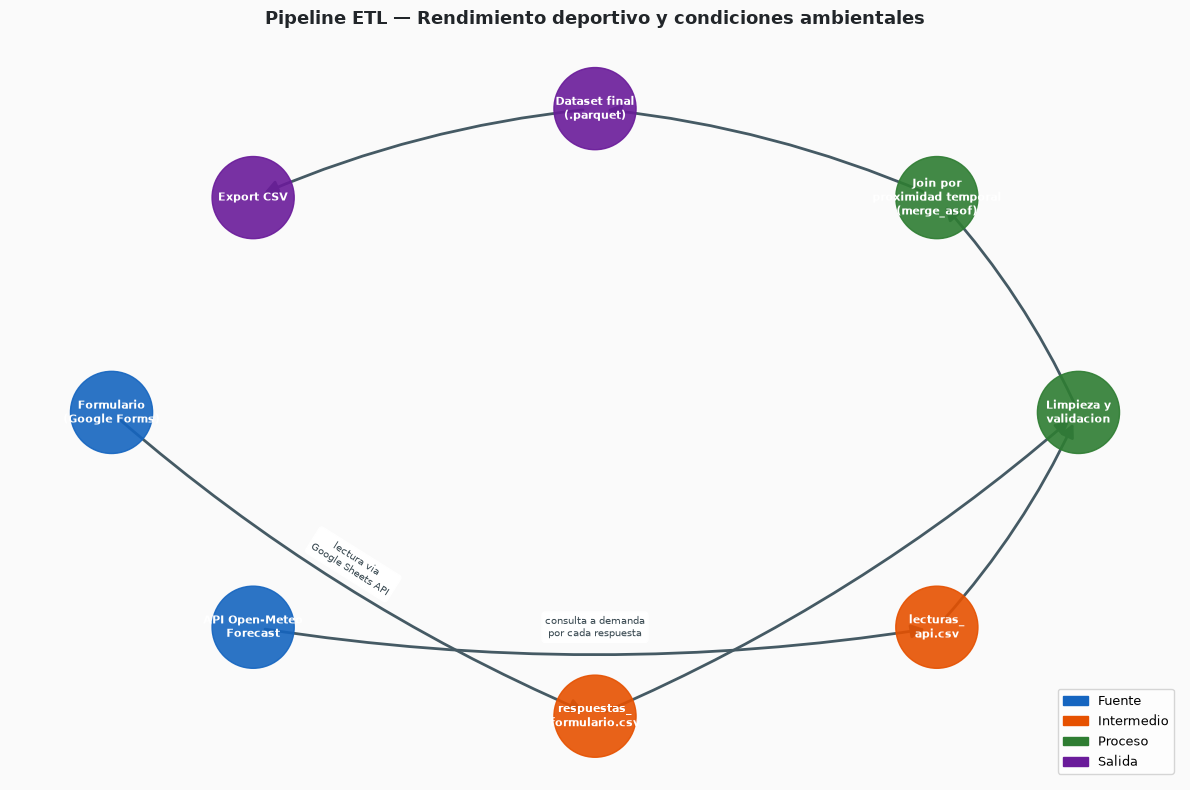

In [5]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

G = nx.DiGraph()

# ── NODOS ────────────────────────────────────────────────────────────────
nodos = [
    # (nombre_nodo,                          grupo)
    ('Formulario\n(Google Forms)',           'fuente'),
    ('API Open-Meteo\nForecast',             'fuente'),
    ('respuestas_\nformulario.csv',          'intermedio'),
    ('lecturas_\napi.csv',                   'intermedio'),
    ('Limpieza y\nvalidacion',               'proceso'),
    ('Join por\nproximidad temporal\n(merge_asof)', 'proceso'),
    ('Dataset final\n(.parquet)',            'salida'),
    ('Export CSV',                           'salida'),
]

# ── ARISTAS ──────────────────────────────────────────────────────────────
aristas = [
    ('Formulario\n(Google Forms)',   'respuestas_\nformulario.csv',  'lectura via\nGoogle Sheets API'),
    ('API Open-Meteo\nForecast',     'lecturas_\napi.csv',           'consulta a demanda\npor cada respuesta'),
    ('respuestas_\nformulario.csv',  'Limpieza y\nvalidacion',       ''),
    ('lecturas_\napi.csv',           'Limpieza y\nvalidacion',       ''),
    ('Limpieza y\nvalidacion',       'Join por\nproximidad temporal\n(merge_asof)', ''),
    ('Join por\nproximidad temporal\n(merge_asof)', 'Dataset final\n(.parquet)', ''),
    ('Dataset final\n(.parquet)',    'Export CSV',                    ''),
]

# ── COLORES POR GRUPO ────────────────────────────────────────────────────
colores_grupo = {
    'fuente':      '#1565C0',
    'intermedio':  '#E65100',
    'proceso':     '#2E7D32',
    'salida':      '#6A1B9A',
}
color_nodo = {n: colores_grupo[g] for n, g in nodos}

G.add_nodes_from([n for n, _ in nodos])
G.add_edges_from([(o, d) for o, d, _ in aristas])

# ── LAYOUT ───────────────────────────────────────────────────────────────
pos = nx.drawing.layout.shell_layout(G)
# Layout manual (descomenta si el automático no queda bien):
# pos = {
#     'Formulario\n(Google Forms)':           (0, 3),
#     'API Open-Meteo\nForecast':             (4, 3),
#     'respuestas_\nformulario.csv':          (0, 1.5),
#     'lecturas_\napi.csv':                   (4, 1.5),
#     'Limpieza y\nvalidacion':               (2, 0.5),
#     'Join por\nproximidad temporal\n(merge_asof)': (2, -0.8),
#     'Dataset final\n(.parquet)':            (2, -2.2),
#     'Export CSV':                           (2, -3.5),
# }

fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

nx.draw_networkx_nodes(G, pos, ax=ax,
    node_color=[color_nodo[n] for n in G.nodes()],
    node_size=3500, alpha=0.9)

nx.draw_networkx_labels(G, pos, ax=ax,
    font_color='white', font_size=8, font_weight='bold')

nx.draw_networkx_edges(G, pos, ax=ax,
    edge_color='#455A64', arrows=True,
    arrowsize=20, width=2,
    connectionstyle='arc3,rad=0.08')

etiquetas_aristas = {(o, d): lbl for o, d, lbl in aristas if lbl}
nx.draw_networkx_edge_labels(G, pos, etiquetas_aristas, ax=ax,
    font_size=7, font_color='#37474F')

leyenda = [mpatches.Patch(color=c, label=g.capitalize())
           for g, c in colores_grupo.items()]
ax.legend(handles=leyenda, loc='lower right', fontsize=9)
ax.set_title('Pipeline ETL — Rendimiento deportivo y condiciones ambientales',
             fontsize=13, fontweight='bold', color='#212529', pad=15)
ax.axis('off')
plt.tight_layout()
plt.show()


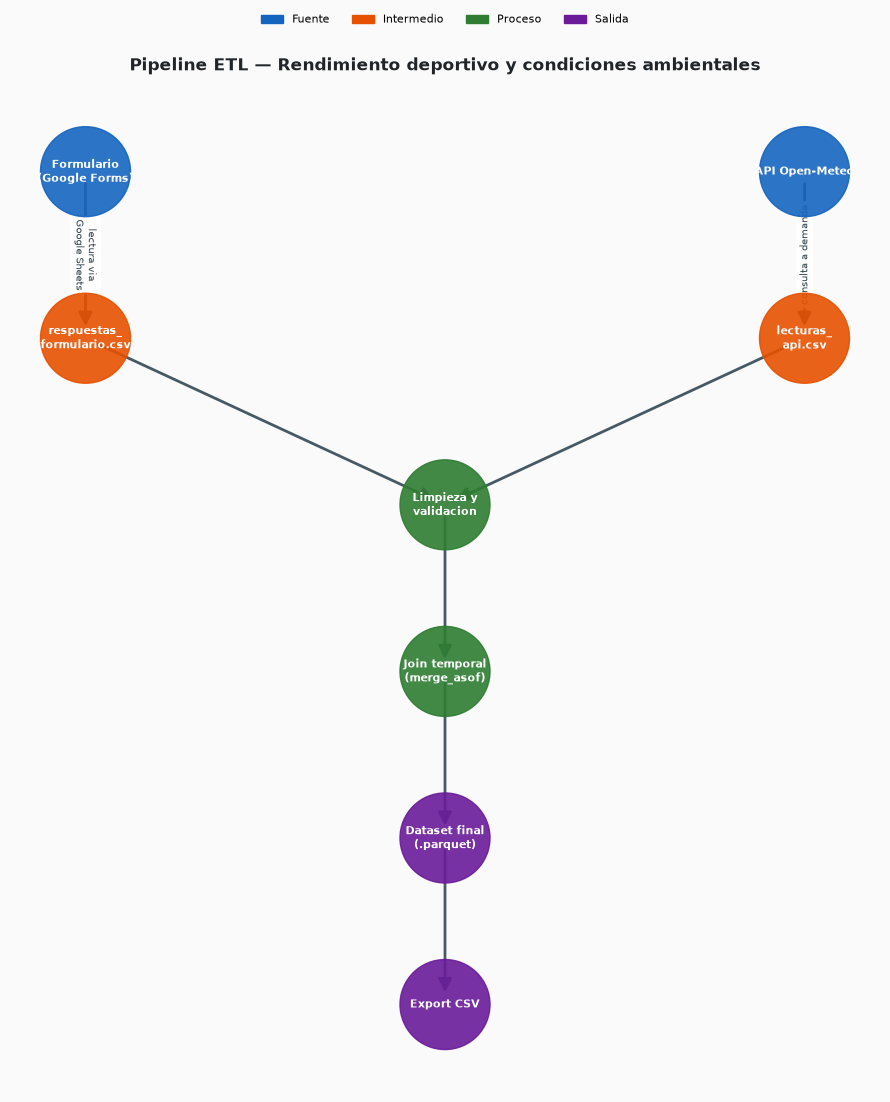

In [4]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

G = nx.DiGraph()

# ── NODOS ────────────────────────────────────────────────────────────────
nodos = [
    # (nombre_nodo,                 grupo)
    ('Formulario\n(Google Forms)',  'fuente'),
    ('API Open-Meteo',              'fuente'),
    ('respuestas_\nformulario.csv', 'intermedio'),
    ('lecturas_\napi.csv',          'intermedio'),
    ('Limpieza y\nvalidacion',      'proceso'),
    ('Join temporal\n(merge_asof)', 'proceso'),
    ('Dataset final\n(.parquet)',   'salida'),
    ('Export CSV',                  'salida'),
]

# ── ARISTAS ──────────────────────────────────────────────────────────────
aristas = [
    ('Formulario\n(Google Forms)',  'respuestas_\nformulario.csv', 'lectura via\nGoogle Sheets'),
    ('API Open-Meteo',              'lecturas_\napi.csv',           'consulta a demanda'),
    ('respuestas_\nformulario.csv', 'Limpieza y\nvalidacion',       ''),
    ('lecturas_\napi.csv',          'Limpieza y\nvalidacion',       ''),
    ('Limpieza y\nvalidacion',      'Join temporal\n(merge_asof)', ''),
    ('Join temporal\n(merge_asof)', 'Dataset final\n(.parquet)',   ''),
    ('Dataset final\n(.parquet)',   'Export CSV',                   ''),
]

# ── COLORES POR GRUPO ────────────────────────────────────────────────────
colores_grupo = {
    'fuente':      '#1565C0',
    'intermedio':  '#E65100',
    'proceso':     '#2E7D32',
    'salida':      '#6A1B9A',
}
color_nodo = {n: colores_grupo[g] for n, g in nodos}

G.add_nodes_from([n for n, _ in nodos])
G.add_edges_from([(o, d) for o, d, _ in aristas])

# ── LAYOUT MANUAL (de arriba a abajo, sigue el flujo del pipeline) ───────
pos = {
    'Formulario\n(Google Forms)':  (-2, 4),
    'API Open-Meteo':              (2, 4),
    'respuestas_\nformulario.csv': (-2, 2.5),
    'lecturas_\napi.csv':          (2, 2.5),
    'Limpieza y\nvalidacion':      (0, 1),
    'Join temporal\n(merge_asof)': (0, -0.5),
    'Dataset final\n(.parquet)':   (0, -2),
    'Export CSV':                  (0, -3.5),
}

fig, ax = plt.subplots(figsize=(9, 11))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

nx.draw_networkx_nodes(G, pos, ax=ax,
    node_color=[color_nodo[n] for n in G.nodes()],
    node_size=4200, alpha=0.9)

nx.draw_networkx_labels(G, pos, ax=ax,
    font_color='white', font_size=8, font_weight='bold')

nx.draw_networkx_edges(G, pos, ax=ax,
    edge_color='#455A64', arrows=True,
    arrowsize=20, width=2,
    connectionstyle='arc3,rad=0.0')

etiquetas_aristas = {(o, d): lbl for o, d, lbl in aristas if lbl}
nx.draw_networkx_edge_labels(G, pos, etiquetas_aristas, ax=ax,
    font_size=7, font_color='#37474F')

leyenda = [mpatches.Patch(color=c, label=g.capitalize())
           for g, c in colores_grupo.items()]
ax.legend(handles=leyenda, loc='upper center', bbox_to_anchor=(0.5, 1.08),
          ncol=4, fontsize=8, frameon=False)
ax.set_title('Pipeline ETL — Rendimiento deportivo y condiciones ambientales',
             fontsize=12, fontweight='bold', color='#212529', pad=10)
ax.axis('off')
plt.tight_layout()
plt.show()


---
## 4. Limitaciones y mejoras futuras

Todo pipeline tiene limitaciones. Reflexiona sobre las tuyas y responde:

1. **¿Qué pasaría si la API dejara de estar disponible durante varios días?** ¿Cómo afectaría eso al dataset? ¿Cómo lo manejarías?

2. **¿Qué sesgo podría tener tu dataset?** Por ejemplo: ¿quién rellena el formulario? ¿Es una muestra representativa de la población que te interesa?

3. **¿Qué añadirías si tuvieras más recursos?** Por ejemplo: más fuentes de datos, mayor frecuencia de muestreo, un sistema de alertas automáticas...

*Responde aquí:*



1. Como en la Etapa 2/5 cada fila del formulario se guarda igualmente aunque falle la consulta meteorológica (con los campos climáticos en NaN y un flag clima_disponible = False / api_status = "error"), no se perdería ningún entrenamiento registrado. Sin embargo, durante esos días se acumularía un bloque de filas sin datos ambientales, lo que reduciría el tamaño de muestra (esas filas tendrían que excluirse o tratarse aparte). Para mitigarlo, implementaría un proceso de reprocesado de alguna manera, y así rellenar a posteriori los huecos sin tener que descartar esos registros.

2. **Sesgo de autoselección**: solo participan deportistas voluntarios motivados a rellenar el formulario, probablemente personas más disciplinadas o con mejor condición física que la población general, lo que no sería representativo de "cualquier persona que hace deporte".

    **Sesgo de ubicación**: si el grupo de deportistas entrena mayoritariamente en Granada o alrededores, el rango de condiciones climáticas (calor seco, poca humedad) sería muy limitado y no generalizable a otros climas.

    **Sesgo de autoinforme**: el esfuerzo_percibido y la sensacion_general son subjetivos y dependen del estado de ánimo o la memoria del deportista al rellenar el formulario, no son medidas objetivas como la frecuencia cardíaca.

3. **Más fuentes de datos objetivas**: integrar datos de pulsómetros o relojes deportivos (frecuencia cardíaca, GPS, cadencia) vía APIs como Strava o Garmin Connect, para tener métricas de rendimiento objetivas y no solo percepción subjetiva.

    **Mayor frecuencia de muestreo meteorológico**: en vez de una sola lectura al final del entrenamiento, registrar la evolución de temperatura/humedad durante toda la sesión (inicio, mitad, fin), ya que un entrenamiento de 1-2 horas puede variar de maneras muy disstintas.


    **Mayor diversidad geográfica**: ampliar el estudio a deportistas de distintas ciudades/climas para poder generalizar las conclusiones más allá de las condiciones específicas de Granada.
